# Dungeon Master v2: Arquitectura Multi-Agente con Expansión Dinámica del Mundo

**Proyecto Final — NLP (MMIA 6021 4889)**  
**Pablo Encalada**  
**Octubre 2026**

---

## 1. Problema y motivación

En la **v1** demostramos que un agente LangGraph con herramientas supera a un LLM directo en consistencia narrativa (+20 puntos en LLM-as-judge). Sin embargo, el mundo era **estático**: 5 ubicaciones fijas, NPCs predefinidos, sin posibilidad de expansión.

En un juego de D&D real, el DM **inventa** nuevas locaciones, personajes y objetos sobre la marcha cuando el jugador explora. "Busco una puerta escondida" debería generar una nueva rama de la historia, no un "no hay nada aquí".

### Diseño experimental v2

| | v1 (Agente simple) | v2 (Multi-agente) |
|---|---|---|
| **Arquitectura** | 1 nodo agente + ToolNode | 3 nodos especializados: Narrator, WorldBuilder, Coherence |
| **Mundo** | Estático (5 ubicaciones fijas) | Dinámico (se expande con `create_location`, `create_npc`, `create_item`) |
| **Flujo** | agent → tools → agent | narrator → ¿expandir? → world_builder → coherence → narrator |
| **Evaluación** | Keywords + LLM-as-judge | Misma + métricas de expansión (nuevas zonas creadas, coherencia del mundo expandido) |

In [1]:
import time, random, re, json, textwrap, copy, math, unicodedata
from typing import Annotated, TypedDict, Literal
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

from langchain_ollama import ChatOllama
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage, ToolMessage
from langchain_core.tools import tool

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode

from openai import OpenAI

print("Imports OK")

Imports OK


In [2]:
# ────────────────────────────────────────────────────────────────────────────
# Configuración del LLM
# ────────────────────────────────────────────────────────────────────────────

OLLAMA_MODEL = "qwen2.5:latest"  # 7B Q4_K_M
OLLAMA_BASE_URL = "http://127.0.0.1:11500"

llm = ChatOllama(model=OLLAMA_MODEL, base_url=OLLAMA_BASE_URL, temperature=0.7)
llm_creative = ChatOllama(model=OLLAMA_MODEL, base_url=OLLAMA_BASE_URL, temperature=0.9)  # más creativo para WorldBuilder
llm_strict = ChatOllama(model=OLLAMA_MODEL, base_url=OLLAMA_BASE_URL, temperature=0.1)    # más determinista para Coherence

try:
    resp = llm.invoke("Di solo OK")
    print(f"Ollama conectado. Modelo: {OLLAMA_MODEL}")
    print(f"Tres perfiles de temperatura: narrator=0.7, world_builder=0.9, coherence=0.1")
except Exception as e:
    print(f"ERROR: {e}")

Ollama conectado. Modelo: qwen2.5:latest
Tres perfiles de temperatura: narrator=0.7, world_builder=0.9, coherence=0.1


## 2. Mundo dinámico

El mundo inicial es el mismo que v1 (5 ubicaciones), pero ahora el `game_state` incluye un **mundo mutable** que puede crecer durante la partida. Las nuevas ubicaciones, NPCs y objetos creados por el WorldBuilder se registran en `game_state["world"]`.

In [3]:
# ────────────────────────────────────────────────────────────────────────────
# Definición del mundo (inicial — puede crecer dinámicamente)
# ────────────────────────────────────────────────────────────────────────────

WORLD_INITIAL = {
    "locations": {
        "taberna": {
            "description": "Una taberna calida con olor a estofado. Un fuego crepita en la chimenea.",
            "connections": ["plaza", "bosque"],
            "items": ["antorcha"],
            "npcs": ["Goruk el tabernero"],
            "dynamic": False,
        },
        "plaza": {
            "description": "La plaza central del pueblo. Una fuente de piedra en el centro.",
            "connections": ["taberna", "herreria", "bosque"],
            "items": [],
            "npcs": ["Elena la comerciante"],
            "dynamic": False,
        },
        "herreria": {
            "description": "El calor del horno es sofocante. Espadas y escudos cuelgan de las paredes.",
            "connections": ["plaza"],
            "items": ["escudo de hierro"],
            "npcs": ["Bron el herrero"],
            "dynamic": False,
        },
        "bosque": {
            "description": "Arboles altos bloquean la luz. Se escuchan ruidos entre la maleza.",
            "connections": ["plaza", "taberna", "cueva"],
            "items": ["hierbas medicinales"],
            "npcs": [],
            "dynamic": False,
        },
        "cueva": {
            "description": "Una cueva oscura y humeda. Huesos viejos esparcidos por el suelo.",
            "connections": ["bosque"],
            "items": ["cofre con 50 monedas de oro"],
            "npcs": ["Goblin centinela"],
            "dynamic": False,
        },
    },
    "npcs": {
        "Goruk el tabernero": {
            "dialogue": "Bienvenido, viajero. Ten cuidado en el bosque.",
            "hostile": False,
        },
        "Elena la comerciante": {
            "dialogue": "Vendo pociones por 10 monedas de oro.",
            "hostile": False,
        },
        "Bron el herrero": {
            "dialogue": "Puedo afilar tu espada por 5 monedas de oro.",
            "hostile": False,
        },
        "Goblin centinela": {
            "dialogue": "¡Intruso! ¡Este es MI tesoro!",
            "hostile": True, "hp": 12, "attack": "1d6", "defense": 10,
        },
    },
}

INITIAL_STATE = {
    "player_name": "Aventurero",
    "hp": 20, "max_hp": 20, "gold": 15,
    "inventory": ["espada oxidada", "pocion de curacion"],
    "location": "taberna",
    "events": [],
    "items_taken": [], "enemies_defeated": [],
}

print("Mundo inicial (5 ubicaciones — puede crecer):")
for loc, data in WORLD_INITIAL["locations"].items():
    conns = ", ".join(data["connections"])
    print(f"  {loc:<12} -> {conns}")

Mundo inicial (5 ubicaciones — puede crecer):
  taberna      -> plaza, bosque
  plaza        -> taberna, herreria, bosque
  herreria     -> plaza
  bosque       -> plaza, taberna, cueva
  cueva        -> bosque


## 3. Herramientas del Narrator + herramientas del WorldBuilder

Separamos las herramientas en dos grupos:
- **Narrator tools**: las mismas de v1 (`check_state`, `move_to`, `attack_enemy`, etc.)
- **WorldBuilder tools**: nuevas herramientas para expandir el mundo (`create_location`, `create_npc`, `create_item`)

In [4]:
# ────────────────────────────────────────────────────────────────────────────
# Estado mutable del juego + mundo dinámico
# ────────────────────────────────────────────────────────────────────────────

game_state = {}
world = {}  # mundo mutable (copia de WORLD_INITIAL + expansiones)


def reset_game():
    """Reinicia estado del jugador y mundo."""
    global game_state, world
    game_state = {
        "hp": INITIAL_STATE["hp"], "max_hp": INITIAL_STATE["max_hp"],
        "gold": INITIAL_STATE["gold"],
        "inventory": list(INITIAL_STATE["inventory"]),
        "location": INITIAL_STATE["location"],
        "events": [], "items_taken": [], "enemies_defeated": [],
        "locations_created": [],  # tracking de expansiones
        "npcs_created": [],
        "items_created": [],
        "turn": 0,          # contador de jugadas (para fechar lo creado)
        "chronicle": "",    # crónica: resumen de lo que salió de la ventana de contexto
    }
    world = copy.deepcopy(WORLD_INITIAL)
    # Registro del mundo: cada entidad guarda sus características, dónde está,
    # cuándo se creó y su estado. Vive en Python, no en el contexto del LLM.
    for loc, data in world["locations"].items():
        data.setdefault("created_turn", 0)
        for npc in data["npcs"]:
            world["npcs"][npc].update({"location": loc, "status": "presente",
                                       "dynamic": False, "created_turn": 0})
            world["npcs"][npc].setdefault("description", world["npcs"][npc]["dialogue"])
    world["items"] = {}
    for loc, data in world["locations"].items():
        for item in data["items"]:
            world["items"][item] = {"description": "", "location": loc,
                                    "status": "en el lugar", "dynamic": False, "created_turn": 0}


def _roll(notation: str) -> int:
    notation = notation.strip().lower()
    m = re.match(r"(\d+)d(\d+)([+-]\d+)?", notation)
    if not m:
        return random.randint(1, 20)
    n, sides, mod = int(m.group(1)), int(m.group(2)), int(m.group(3) or 0)
    return sum(random.randint(1, sides) for _ in range(n)) + mod


def _state_summary() -> str:
    inv = ", ".join(game_state["inventory"]) if game_state["inventory"] else "(vacio)"
    return (
        f"[HP: {game_state['hp']}/{game_state['max_hp']} | "
        f"Oro: {game_state['gold']} | "
        f"Ubicacion: {game_state['location']} | "
        f"Inventario: {inv}]"
    )


def _world_summary() -> str:
    locs = list(world["locations"].keys())
    dynamic = [l for l, d in world["locations"].items() if d.get("dynamic")]
    return f"Ubicaciones: {len(locs)} ({len(dynamic)} creadas dinámicamente): {', '.join(locs)}"


def _world_memory() -> str:
    """Memoria compacta del mundo para los system prompts.
    Siempre incluye lo creado dinámicamente, los NPCs y la crónica,
    aunque los mensajes donde ocurrió ya no estén en la ventana de contexto."""
    lines = []
    dyn_locs = [(k, v) for k, v in world["locations"].items() if v.get("dynamic")]
    if dyn_locs:
        lines.append("Lugares descubiertos:")
        for k, v in dyn_locs:
            lines.append(f"- {k} (jugada {v['created_turn']}, conecta con {', '.join(v['connections'])}): "
                         f"{v['description'][:100]}")
    dyn_npcs = [(k, v) for k, v in world["npcs"].items() if v.get("dynamic")]
    if dyn_npcs:
        lines.append("Personajes creados:")
        for k, v in dyn_npcs:
            lines.append(f"- {k} en {v['location']} ({'hostil' if v['hostile'] else 'amigable'}, "
                         f"{v['status']}): {v['description'][:80]}")
    dyn_items = [(k, v) for k, v in world["items"].items() if v.get("dynamic")]
    if dyn_items:
        lines.append("Objetos creados: " + "; ".join(f"{k} ({v['location']}, {v['status']})"
                                                      for k, v in dyn_items))
    if game_state["chronicle"]:
        lines.append(f"Crónica:\n{game_state['chronicle']}")
    return "\n".join(lines) or "(nada creado todavía)"


def _similar_location(key: str):
    """Devuelve una ubicación existente con nombre casi igual (evita duplicados)."""
    words = set(key.split("_"))
    for existing in world["locations"]:
        ex_words = set(existing.split("_"))
        overlap = len(words & ex_words) / max(len(words | ex_words), 1)
        if overlap >= 0.5 and world["locations"][existing].get("dynamic"):
            return existing
    return None


# ── Narrator tools (mismas de v1) ──────────────────────────────────────────

@tool
def roll_dice(notation: str) -> str:
    """Tira dados con notacion estandar (ej: '1d20', '2d6+3')."""
    return f"Tiraste {notation}: resultado = {_roll(notation)}"


@tool
def check_state() -> str:
    """Consulta el estado actual del jugador: HP, oro, inventario, ubicacion y conexiones."""
    loc = game_state["location"]
    loc_data = world["locations"][loc]
    available_items = [i for i in loc_data["items"] if i not in game_state["items_taken"]]
    npcs_here = [n for n in loc_data["npcs"] if n not in game_state["enemies_defeated"]]
    connections = ", ".join(loc_data["connections"])
    return (
        f"Estado del jugador: {_state_summary()}\n"
        f"Descripcion del lugar: {loc_data['description']}\n"
        f"Objetos aqui: {available_items or 'ninguno'}\n"
        f"NPCs aqui: {npcs_here or 'nadie'}\n"
        f"Puedes ir a: {connections}\n"
        f"Eventos previos: {game_state['events'][-5:] if game_state['events'] else 'ninguno'}\n"
        f"Mundo: {_world_summary()}"
    )


@tool
def consult_world(topic: str = "") -> str:
    """Consulta el registro permanente del mundo: lugares descubiertos, personajes, objetos,
    todos los eventos y la cronica de la aventura. Usalo cuando el jugador pregunte por el
    pasado, por lugares o personajes que ya conocio, o pida un resumen. 'topic' filtra
    (ej: 'goblin', 'sendero'); vacio devuelve todo."""
    t = topic.strip().lower()
    match = lambda *texts: not t or any(t in str(x).lower() for x in texts)
    out = []
    locs = [f"- {k}{' [descubierto en jugada ' + str(v['created_turn']) + ']' if v.get('dynamic') else ''}: "
            f"{v['description']} Conecta con: {', '.join(v['connections'])}"
            for k, v in world["locations"].items() if match(k, v["description"])]
    if locs:
        out.append("LUGARES:\n" + "\n".join(locs))
    npcs = [f"- {k} ({v['location']}, {'hostil' if v['hostile'] else 'amigable'}, {v['status']}): "
            f"{v['description']}"
            for k, v in world["npcs"].items() if match(k, v["description"], v["location"])]
    if npcs:
        out.append("PERSONAJES:\n" + "\n".join(npcs))
    items = [f"- {k} ({v['location']}, {v['status']}) {v['description']}"
             for k, v in world["items"].items() if match(k, v["description"], v["location"])]
    if items:
        out.append("OBJETOS:\n" + "\n".join(items))
    events = [e for e in game_state["events"] if match(e)]
    if events:
        out.append("EVENTOS:\n" + "\n".join(f"- {e}" for e in events))
    if game_state["chronicle"] and not t:
        out.append("CRONICA:\n" + game_state["chronicle"])
    return "\n\n".join(out) or f"No hay nada registrado sobre '{topic}'."


@tool
def move_to(destination: str) -> str:
    """Mueve al jugador a una ubicacion conectada."""
    dest = destination.strip().lower()
    current = game_state["location"]
    connections = world["locations"][current]["connections"]
    if dest not in connections:
        return f"No puedes ir a '{dest}' desde {current}. Destinos validos: {', '.join(connections)}"
    game_state["location"] = dest
    game_state["events"].append(f"Se movio de {current} a {dest}")
    loc_data = world["locations"][dest]
    npcs = [n for n in loc_data["npcs"] if n not in game_state["enemies_defeated"]]
    items = [i for i in loc_data["items"] if i not in game_state["items_taken"]]
    return (
        f"Te mueves a: {dest}. {loc_data['description']}\n"
        f"NPCs aqui: {npcs or 'nadie'}. Objetos: {items or 'ninguno'}.\n"
        f"{_state_summary()}"
    )


@tool
def pick_up_item(item_name: str) -> str:
    """Recoge un objeto de la ubicacion actual."""
    item = item_name.strip().lower()
    loc = game_state["location"]
    available = [i for i in world["locations"][loc]["items"] if i not in game_state["items_taken"]]
    available_lower = [i.lower() for i in available]
    if item not in available_lower:
        return f"No hay '{item}' aqui. Objetos disponibles: {available or 'ninguno'}"
    idx = available_lower.index(item)
    real_name = available[idx]
    game_state["inventory"].append(real_name)
    game_state["items_taken"].append(real_name)
    game_state["events"].append(f"Recogio: {real_name}")
    if real_name in world["items"]:
        world["items"][real_name]["status"] = "en el inventario"
    return f"Recogiste: {real_name}. {_state_summary()}"


@tool
def use_potion() -> str:
    """Usa una pocion de curacion del inventario."""
    if "pocion de curacion" not in game_state["inventory"]:
        return f"No tienes pociones. Inventario: {game_state['inventory']}"
    heal = _roll("2d4+2")
    game_state["inventory"].remove("pocion de curacion")
    old_hp = game_state["hp"]
    game_state["hp"] = min(game_state["hp"] + heal, game_state["max_hp"])
    game_state["events"].append(f"Uso pocion: +{heal} HP ({old_hp} -> {game_state['hp']})")
    return f"Bebiste la pocion. Recuperas {heal} HP. {_state_summary()}"


@tool
def attack_enemy(enemy_name: str) -> str:
    """Resuelve un turno de combate contra un enemigo."""
    loc = game_state["location"]
    npcs_here = [n for n in world["locations"][loc].get("npcs", [])
                 if n not in game_state["enemies_defeated"]]
    enemy = None
    for npc in npcs_here:
        if enemy_name.lower() in npc.lower():
            enemy = npc
            break
    if not enemy:
        return f"No hay enemigo '{enemy_name}' aqui. NPCs: {npcs_here or 'nadie'}"
    npc_data = world["npcs"][enemy]
    if not npc_data.get("hostile", False):
        return f"{enemy} no es hostil."
    player_roll = _roll("1d20")
    player_hits = player_roll >= 10
    player_dmg = _roll("1d6") if player_hits else 0
    enemy_roll = _roll("1d20")
    enemy_hits = enemy_roll >= 10
    enemy_dmg = _roll(npc_data.get("attack", "1d6")) if enemy_hits else 0
    result = f"--- COMBATE vs {enemy} ---\n"
    result += f"Tu ataque: d20={player_roll} -> {'ACIERTO' if player_hits else 'FALLO'}"
    if player_hits:
        result += f", {player_dmg} de dano"
    result += f"\nAtaque de {enemy}: d20={enemy_roll} -> {'ACIERTO' if enemy_hits else 'FALLO'}"
    if enemy_hits:
        game_state["hp"] = max(0, game_state["hp"] - enemy_dmg)
        result += f", {enemy_dmg} de dano a ti"
    if player_hits:
        game_state["enemies_defeated"].append(enemy)
        game_state["events"].append(f"Derroto a {enemy}")
        world["npcs"][enemy]["status"] = "derrotado"
        result += f"\n¡{enemy} ha sido derrotado!"
    else:
        game_state["events"].append(f"Combate con {enemy}: fallo")
        result += f"\n{enemy} sigue en pie."
    result += f"\n{_state_summary()}"
    return result


# ── WorldBuilder tools (NUEVAS en v2) ─────────────────────────────────────

@tool
def create_location(name: str, description: str, connected_to: str) -> str:
    """Crea una nueva ubicacion en el mundo y la conecta a una ubicacion existente.
    Usa esto cuando el jugador descubre un lugar nuevo (puerta escondida, pasadizo, etc.).
    El nombre debe ser en minusculas sin acentos (ej: 'pasadizo_secreto')."""
    key = name.strip().lower().replace(" ", "_")
    # Lo que se descubre está donde está el jugador (si no, sería inalcanzable)
    parent = game_state["location"]
    if key in world["locations"]:
        return f"La ubicacion '{key}' ya existe."
    similar = _similar_location(key)
    if similar:
        return (f"NO CREADA: ya existe '{similar}', muy parecida a '{key}'. "
                f"Reutiliza '{similar}' en vez de duplicarla.")
    if parent not in world["locations"]:
        return f"La ubicacion '{parent}' no existe. Ubicaciones: {list(world['locations'].keys())}"
    world["locations"][key] = {
        "description": description,
        "connections": [parent],
        "items": [],
        "npcs": [],
        "dynamic": True,
        "created_turn": game_state["turn"],
    }
    world["locations"][parent]["connections"].append(key)
    game_state["locations_created"].append(key)
    game_state["events"].append(f"Descubrio nueva ubicacion: {key} (conectada a {parent})")
    return (
        f"NUEVA UBICACION CREADA: '{key}'\n"
        f"Descripcion: {description}\n"
        f"Conectada a: {parent} (bidireccional)\n"
        f"Ahora puedes moverte ahi con move_to.\n"
        f"{_world_summary()}"
    )


@tool
def create_npc(name: str, description: str, location: str, hostile: bool) -> str:
    """Crea un nuevo NPC en una ubicacion. Usa esto para poblar zonas nuevas o añadir
    personajes cuando el jugador busca interaccion."""
    loc = location.strip().lower()
    if loc not in world["locations"]:
        return f"La ubicacion '{loc}' no existe."
    if name in world["npcs"]:
        return f"El NPC '{name}' ya existe."
    npc_data = {"dialogue": description, "description": description, "hostile": hostile,
                "location": loc, "status": "presente", "dynamic": True,
                "created_turn": game_state["turn"]}
    if hostile:
        npc_data.update({"hp": random.randint(8, 15), "attack": "1d6", "defense": 10})
    world["npcs"][name] = npc_data
    world["locations"][loc]["npcs"].append(name)
    game_state["npcs_created"].append(name)
    game_state["events"].append(f"Nuevo NPC: {name} en {loc}")
    return f"NPC CREADO: '{name}' en {loc} ({'hostil' if hostile else 'amigable'}). {description}"


@tool
def create_item(name: str, description: str, location: str) -> str:
    """Crea un nuevo objeto en una ubicacion. Usa esto para añadir tesoros, llaves,
    armas u otros objetos interesantes."""
    loc = location.strip().lower()
    if loc not in world["locations"]:
        return f"La ubicacion '{loc}' no existe."
    world["locations"][loc]["items"].append(name)
    world["items"][name] = {"description": description, "location": loc, "status": "en el lugar",
                            "dynamic": True, "created_turn": game_state["turn"]}
    game_state["items_created"].append(name)
    game_state["events"].append(f"Nuevo objeto: {name} en {loc}")
    return f"OBJETO CREADO: '{name}' en {loc}. {description}"


# Dos conjuntos de herramientas
NARRATOR_TOOLS = [roll_dice, check_state, move_to, pick_up_item, use_potion, attack_enemy, consult_world]
V1_TOOLS = [roll_dice, check_state, move_to, pick_up_item, use_potion, attack_enemy]  # v1 sin memoria
WORLD_TOOLS = [create_location, create_npc, create_item, check_state]
ALL_TOOLS = list({t.name: t for t in NARRATOR_TOOLS + WORLD_TOOLS}.values())

print(f"Narrator tools: {[t.name for t in NARRATOR_TOOLS]}")
print(f"WorldBuilder tools: {[t.name for t in WORLD_TOOLS]}")
print(f"Total herramientas únicas: {len(ALL_TOOLS)}")

Narrator tools: ['roll_dice', 'check_state', 'move_to', 'pick_up_item', 'use_potion', 'attack_enemy', 'consult_world']
WorldBuilder tools: ['create_location', 'create_npc', 'create_item', 'check_state']
Total herramientas únicas: 10


## 4. Grafo Multi-Agente LangGraph

El grafo tiene 3 nodos especializados:

```
START → narrator → should_use_tools? → narrator_tools → narrator
                 → should_expand?    → world_builder → wb_tools → coherence_check → narrator
                 → END
```

1. **Narrator**: narra la historia, usa herramientas de juego (check_state, move_to, etc.)
2. **WorldBuilder**: se activa cuando el jugador explora algo nuevo; crea ubicaciones/NPCs/items
3. **CoherenceChecker**: valida que la expansión sea consistente con el mundo existente

In [5]:
# ────────────────────────────────────────────────────────────────────────────
# 4. Grafo Multi-Agente
# ────────────────────────────────────────────────────────────────────────────

class AgentState(TypedDict):
    messages: Annotated[list, add_messages]
    needs_expansion: bool  # flag para activar WorldBuilder
    expansions: int        # expansiones en esta jugada (máximo 1)
    wb_steps: int          # rondas de herramientas del WorldBuilder (máximo 3)


MAX_WB_STEPS = 3
EXPLORACION = re.compile(r"busc|examin|explor|investig|escondid|secret|ocult|rastre", re.IGNORECASE)
# qwen2.5:7b a veces escribe la llamada como texto ("CallCheckState();", {"name": ...}) en vez de hacerla
MOVIMIENTO = re.compile(r"^\s*(voy|vuelvo|regreso|entro|camino|me muevo|ir a)\b", re.IGNORECASE)
FAKE_TOOL_CALL = re.compile(r"call\s*_?check|check_?state\s*\(|\"name\"\s*:\s*\"", re.IGNORECASE)


# ── System prompts especializados ─────────────────────────────────────────

SYSTEM_NARRATOR = """\
Eres el Narrator, un Dungeon Master de D&D que narra en español.

INSTRUCCIONES OBLIGATORIAS:
1. SIEMPRE llama a check_state PRIMERO.
2. Si el jugador quiere MOVERSE, usa move_to (NUNCA narres movimiento sin la herramienta).
3. Si el jugador quiere RECOGER algo, usa pick_up_item.
4. Si el jugador quiere ATACAR, usa attack_enemy.
5. Si el jugador quiere CURARSE, usa use_potion.
6. Para tiradas de dados, usa roll_dice.
7. Después de usar herramientas, narra brevemente (2-3 oraciones) y muestra el estado.
8. Si el jugador pregunta por el PASADO (lugares descubiertos, personajes, eventos, resumen),
   usa consult_world. La MEMORIA DEL MUNDO de abajo es la verdad, aunque no recuerdes la conversación.

Si check_state muestra un DESCUBRIMIENTO, narra ese descubrimiento al jugador.
Si el jugador busca algo y no hay DESCUBRIMIENTO, narra que no encuentra nada
(no inventes lugares ni personajes).
Si aun así falta algo que el jugador busca, incluye la frase exacta:
[EXPANDIR_MUNDO] seguida de qué necesita ser creado.
NO pidas expansión si lo que busca ya aparece en la MEMORIA DEL MUNDO: úsalo.

NUNCA respondas sin usar check_state primero."""

SYSTEM_WORLD_BUILDER = """\
Eres el WorldBuilder, un diseñador creativo de mundos de D&D.

Tu trabajo es expandir el mundo cuando el jugador busca o explora algo nuevo.
Tienes acceso a herramientas para crear ubicaciones, NPCs y objetos.
Si lo que busca ya existe en la MEMORIA DEL MUNDO o no tiene sentido crearlo, no crees nada
y explica brevemente por qué.

REGLAS:
1. Las nuevas ubicaciones deben conectarse a una ubicación existente.
2. Los nombres deben ser en minúsculas sin acentos (ej: 'pasadizo_secreto').
3. Crea contenido temáticamente coherente con el mundo (fantasía medieval).
4. Cada nueva ubicación debe tener al menos 1 elemento interesante (NPC, item, o peligro).
5. Crea como máximo 1 ubicación por petición.
6. NO dupliques: si ya existe un lugar parecido en el MUNDO ACTUAL, no crees otro.
7. Sé creativo pero mantén el tono del mundo y lo que ya existe en la memoria.

Después de crear, describe brevemente lo que creaste."""

SYSTEM_COHERENCE = """\
Eres el verificador de coherencia. Revisa que las expansiones del mundo sean consistentes.

Dado el estado actual del mundo y las nuevas adiciones, verifica:
1. ¿Las conexiones tienen sentido geográficamente?
2. ¿Los NPCs y objetos son temáticamente apropiados?
3. ¿Hay contradicciones con el mundo existente o con la crónica?
4. ¿Hay lugares duplicados (mismo sitio con distinto nombre)?

Si todo es coherente, responde: [COHERENTE] y un breve resumen.
Si hay problemas, responde: [INCOHERENTE] y explica qué corregir."""


# ── LLMs con herramientas ─────────────────────────────────────────────────

llm_narrator = llm.bind_tools(NARRATOR_TOOLS)
llm_world_builder = llm_creative.bind_tools(WORLD_TOOLS)


# ── Separar la conversación del narrator del trabajo de los otros agentes ──

def _narrator_messages(msgs):
    """Mensajes que ve el narrator: los suyos con tool calls y resultados (le sirven de
    ejemplo de cómo usar herramientas), sin los del WorldBuilder/Coherence."""
    keep, call_ids = [], set()
    for m in msgs:
        if isinstance(m, AIMessage):
            if m.name in ("world_builder", "coherence"):
                continue
            call_ids |= {tc["id"] for tc in (m.tool_calls or [])}
        if isinstance(m, ToolMessage) and m.tool_call_id not in call_ids:
            continue
        keep.append(m)
    return keep


def _discoveries_this_turn():
    """Lo creado en esta jugada, leído del registro del mundo."""
    t = game_state["turn"]
    out = [f"Descubres un lugar nuevo: {k} ({v['description']}). Se llega desde: {', '.join(v['connections'])}."
           for k, v in world["locations"].items() if v.get("dynamic") and v["created_turn"] == t]
    out += [f"Aparece un personaje nuevo en {v['location']}: {k} ({v['description']})."
            for k, v in world["npcs"].items() if v.get("dynamic") and v["created_turn"] == t]
    out += [f"Hay un objeto nuevo en {v['location']}: {k} ({v['description']})."
            for k, v in world["items"].items() if v.get("dynamic") and v["created_turn"] == t]
    return out


def _with_discovery(msgs):
    """Si el WorldBuilder creó algo en esta jugada, se lo muestra al narrator como el resultado
    de un check_state justo después de la acción del jugador (los modelos chicos atienden mucho
    más a resultados de herramientas que a avisos en el system prompt)."""
    found = _discoveries_this_turn()
    last_human = max((i for i, m in enumerate(msgs) if isinstance(m, HumanMessage)), default=None)
    if not found or last_human is None:
        return msgs
    call_id = f"discovery_{game_state['turn']}"
    fake_call = AIMessage(content="", tool_calls=[{"name": "check_state", "args": {}, "id": call_id}])
    result = ToolMessage(content=check_state.invoke({}) + "\nDESCUBRIMIENTO:\n" + "\n".join(found),
                         tool_call_id=call_id)
    return msgs[:last_human + 1] + [fake_call, result] + msgs[last_human + 1:]


def _location_in(text):
    """Ubicación conocida mencionada en el texto del jugador (sin acentos), o None."""
    t = unicodedata.normalize("NFKD", text.lower()).encode("ascii", "ignore").decode()
    hits = [k for k in world["locations"] if re.search(rf"\b{re.escape(k.replace('_', ' '))}\b", t.replace("_", " "))]
    return max(hits, key=len) if hits else None


# ── Nodos del grafo ──────────────────────────────────────────────────────

def narrator_node(state: AgentState):
    """Nodo Narrator: narra la historia usando herramientas de juego."""
    state_info = _state_summary()
    world_info = _world_summary()
    system = (SYSTEM_NARRATOR + f"\n\nESTADO: {state_info}\nMUNDO: {world_info}"
              f"\n\nMEMORIA DEL MUNDO:\n{_world_memory()}")
    messages = [SystemMessage(content=system)] + _with_discovery(_narrator_messages(state["messages"]))
    response = llm_narrator.invoke(messages)
    accion = next((m.content for m in reversed(state["messages"]) if isinstance(m, HumanMessage)), "")
    ya_movio = any(tc["name"] == "move_to" for m in _narrator_messages(state["messages"])
                   if isinstance(m, AIMessage) for tc in (m.tool_calls or []))
    if not response.tool_calls and FAKE_TOOL_CALL.search(response.content or ""):
        # Un reintento: pedirle que use la herramienta de verdad
        response = llm_narrator.invoke(messages + [response, HumanMessage(
            content="(sistema) Escribiste la llamada como texto. Usa la herramienta de verdad o narra la respuesta.")])
    elif not response.tool_calls and not ya_movio and MOVIMIENTO.search(accion):
        # El jugador quiere moverse y el narrator respondió sin move_to: un reintento
        response = llm_narrator.invoke(messages + [response, HumanMessage(
            content="(sistema) El jugador quiere moverse: usa move_to con el destino; la herramienta valida si es posible.")])
        destino = _location_in(accion)
        if not response.tool_calls and destino:
            # Último recurso determinista: la acción nombra un lugar conocido → move_to
            # (la herramienta sigue validando si el movimiento es legal)
            response = AIMessage(content="", tool_calls=[{"name": "move_to", "args": {"destination": destino},
                                                          "id": f"forced_move_{game_state['turn']}"}])
    # Detectar si necesita expansión: el narrator lo pide Y el jugador está buscando algo
    # (evita expansiones espurias cuando el jugador solo se mueve o pregunta)
    needs_expansion = "[EXPANDIR_MUNDO]" in (response.content or "") and bool(EXPLORACION.search(accion))
    return {"messages": [response], "needs_expansion": needs_expansion}


def world_builder_node(state: AgentState):
    """Nodo WorldBuilder: crea nuevas ubicaciones, NPCs, objetos."""
    # Buscar la petición del narrator ([EXPANDIR_MUNDO]) y lo que el WorldBuilder
    # ya hizo después (sus tool calls + resultados), para que no repita creaciones
    # (o, si se activó desde START por una acción de exploración, la acción del jugador)
    msgs = state["messages"]
    req_idx = max((i for i, m in enumerate(msgs)
                   if (isinstance(m, AIMessage) and "[EXPANDIR_MUNDO]" in (m.content or ""))
                   or isinstance(m, HumanMessage)), default=None)
    last_content = msgs[req_idx].content if req_idx is not None else ""
    own_work = msgs[req_idx + 1:] if req_idx is not None else []
    world_info = _world_summary()
    loc = game_state["location"]
    loc_data = world["locations"][loc]
    system = (
        SYSTEM_WORLD_BUILDER +
        f"\n\nMUNDO ACTUAL: {world_info}"
        f"\nMEMORIA DEL MUNDO:\n{_world_memory()}"
        f"\nUBICACION ACTUAL: {loc} - {loc_data['description']}"
        f"\nCONEXIONES: {loc_data['connections']}"
        f"\nPETICION DEL NARRATOR: {last_content}"
    )
    messages = [SystemMessage(content=system)] + [
        HumanMessage(content=f"El jugador quiere explorar algo nuevo. Crea el contenido necesario basándote en: {last_content}")
    ] + own_work
    llm_wb = llm_world_builder if state.get("wb_steps", 0) < MAX_WB_STEPS else llm_creative
    response = llm_wb.invoke(messages)
    response.name = "world_builder"
    return {"messages": [response], "needs_expansion": False,
            "expansions": state.get("expansions", 0) + (0 if own_work else 1),
            "wb_steps": state.get("wb_steps", 0) + 1}


def coherence_node(state: AgentState):
    """Nodo Coherence: verifica que la expansión sea consistente."""
    world_info = json.dumps({k: {"desc": v["description"][:60], "conn": v["connections"], "dynamic": v.get("dynamic", False)}
                             for k, v in world["locations"].items()}, ensure_ascii=False)
    recent_events = game_state["events"][-5:]
    system = SYSTEM_COHERENCE
    messages = [SystemMessage(content=system)] + [
        HumanMessage(content=f"Estado del mundo: {world_info}\nEventos recientes: {recent_events}"
                             f"\nCrónica: {game_state['chronicle'] or '(vacía)'}\n¿Es coherente?")
    ]
    response = llm_strict.invoke(messages)
    response.name = "coherence"
    return {"messages": [response]}


# ── Routing ──────────────────────────────────────────────────────────────

def start_router(state: AgentState):
    """Si el jugador está buscando/explorando, el WorldBuilder actúa primero,
    así el narrator narra con el mundo ya expandido (y no 'no encuentras nada')."""
    accion = state["messages"][-1].content if state["messages"] else ""
    return "world_builder" if EXPLORACION.search(accion) else "narrator"


def narrator_router(state: AgentState):
    """Decide: ¿herramientas, expandir mundo, o terminar?"""
    last = state["messages"][-1]
    # Si tiene tool calls, ejecutar herramientas del narrator
    if hasattr(last, "tool_calls") and last.tool_calls:
        return "narrator_tools"
    # Si necesita expansión del mundo (máximo 1 por jugada, evita el ciclo coherence → narrator → WB)
    if state.get("needs_expansion", False) and state.get("expansions", 0) == 0:
        return "world_builder"
    return END


def wb_router(state: AgentState):
    """Decide si WorldBuilder necesita ejecutar sus herramientas."""
    last = state["messages"][-1]
    if hasattr(last, "tool_calls") and last.tool_calls:
        return "wb_tools"
    return "coherence"


# ── Construir el grafo ────────────────────────────────────────────────────

narrator_tool_node = ToolNode(NARRATOR_TOOLS)
wb_tool_node = ToolNode(WORLD_TOOLS)

graph = StateGraph(AgentState)

# Nodos
graph.add_node("narrator", narrator_node)
graph.add_node("narrator_tools", narrator_tool_node)
graph.add_node("world_builder", world_builder_node)
graph.add_node("wb_tools", wb_tool_node)
graph.add_node("coherence", coherence_node)

# Edges
graph.add_conditional_edges(START, start_router, {"world_builder": "world_builder", "narrator": "narrator"})
graph.add_conditional_edges("narrator", narrator_router,
    {"narrator_tools": "narrator_tools", "world_builder": "world_builder", END: END})
graph.add_edge("narrator_tools", "narrator")  # loop: tool results → narrator
graph.add_conditional_edges("world_builder", wb_router,
    {"wb_tools": "wb_tools", "coherence": "coherence"})
graph.add_edge("wb_tools", "world_builder")   # loop: wb tool results → wb
graph.add_edge("coherence", "narrator")        # coherence → narrator para narrar

app_v2 = graph.compile()

print("Grafo Multi-Agente v2 compilado:")
print("  START → (exploración) world_builder → wb_tools → world_builder → coherence → narrator")
print("  START → narrator → narrator_tools → narrator (loop)")
print("                   → world_builder → wb_tools → world_builder (loop)")
print("                                   → coherence → narrator")
print("                   → END")

Grafo Multi-Agente v2 compilado:
  START → (exploración) world_builder → wb_tools → world_builder → coherence → narrator
  START → narrator → narrator_tools → narrator (loop)
                   → world_builder → wb_tools → world_builder (loop)
                                   → coherence → narrator
                   → END


In [6]:
# ────────────────────────────────────────────────────────────────────────────
# 4.1 Wrapper del agente multi-agente
# ────────────────────────────────────────────────────────────────────────────

WINDOW_PLAYS = 3  # jugadas recientes que el LLM ve completas; lo anterior pasa a la crónica

SYSTEM_CRONISTA = """\
Eres el cronista de una partida de D&D. Mantienes una crónica breve con los HECHOS CLAVE de la
narración: lugares visitados o descubiertos y cómo son, personajes conocidos y lo que dijeron de
importante, pistas, promesas, misterios pendientes.
REGLAS:
- Solo hechos que aparecen EXPLÍCITAMENTE en las jugadas o en la crónica actual. No inventes.
- NO incluyas HP, oro ni inventario (eso lo registra el sistema).
- Devuelve SOLO viñetas que empiecen con "- ", máximo 10 viñetas, en español. Sin títulos."""


def update_chronicle(dropped):
    """Incorpora a la crónica las jugadas que salen de la ventana de contexto."""
    texto = "\n".join(f"Jugador: {a}\nDM: {r[:500]}" for a, r in dropped)
    prompt = (f"Crónica actual:\n{game_state['chronicle'] or '(vacía)'}\n\n"
              f"Nuevas jugadas:\n{texto}\n\nDevuelve la crónica actualizada.")
    resp = llm_strict.invoke([SystemMessage(content=SYSTEM_CRONISTA), HumanMessage(content=prompt)])
    bullets = [l.strip() for l in resp.content.splitlines() if l.strip().startswith("- ")]
    game_state["chronicle"] = "\n".join(bullets[:10])


class MultiAgentDM:
    """Dungeon Master multi-agente con mundo dinámico y memoria persistente.

    Memoria en dos niveles:
      - Corto plazo: el LLM ve solo las últimas WINDOW_PLAYS jugadas del narrator (con sus
        tool calls, sin los mensajes de WorldBuilder/Coherence), así el contexto no crece sin límite.
      - Largo plazo: el registro del mundo (world) y la crónica viven en Python y se inyectan
        en los system prompts / se consultan con consult_world.
    """

    def __init__(self, app):
        self.app = app
        self.history = []        # [(acción, respuesta final, mensajes)] dentro de la ventana
        self.turn_times = []
        self.context_tokens = []  # tokens de prompt máximos por jugada (para graficar)
        self.expansion_log = []  # registro de expansiones
        reset_game()

    def play(self, action: str) -> str:
        game_state["turn"] += 1
        window = [m for _, _, msgs in self.history for m in msgs]
        n_prev = len(window)
        state = {"messages": window + [HumanMessage(content=action)],
                 "needs_expansion": False, "expansions": 0, "wb_steps": 0}
        t0 = time.time()
        try:
            result = self.app.invoke(state, {"recursion_limit": 40})
        except Exception as e:  # GraphRecursionError u otro fallo: no romper la partida
            result = {"messages": state["messages"] + [AIMessage(content=f"(error del DM: {type(e).__name__})")]}
        elapsed = time.time() - t0
        self.turn_times.append(elapsed)
        new_msgs = result["messages"][n_prev:]
        self.context_tokens.append(max([(m.usage_metadata or {}).get("input_tokens", 0)
                                        for m in new_msgs if isinstance(m, AIMessage)] or [0]))

        # Registrar si hubo expansión
        new_locs = [l for l in game_state.get("locations_created", [])
                    if l not in [e.get("location") for e in self.expansion_log]]
        for loc in new_locs:
            self.expansion_log.append({
                "location": loc,
                "turn": len(self.turn_times),
                "description": world["locations"].get(loc, {}).get("description", ""),
            })

        # Extraer última respuesta narrativa
        play_msgs = _narrator_messages(new_msgs)
        texts = [m.content.strip() for m in play_msgs
                 if isinstance(m, AIMessage) and m.content and m.content.strip()]
        final = re.sub(r"\[EXPANDIR_MUNDO\][^\n]*\n?", "", "\n\n".join(texts)).strip() or "(sin respuesta)"

        last = play_msgs[-1] if play_msgs else None
        if not (isinstance(last, AIMessage) and not last.tool_calls and last.content):
            play_msgs = play_msgs + [AIMessage(content=final)]

        # Ventana: las últimas jugadas completas del narrator; lo que sale va a la crónica
        self.history.append((action, final, play_msgs))
        if len(self.history) > WINDOW_PLAYS:
            dropped, self.history = self.history[:-WINDOW_PLAYS], self.history[-WINDOW_PLAYS:]
            update_chronicle([(a, r) for a, r, _ in dropped])
        return final


# ── Baseline v1 (para comparar) ──────────────────────────────────────────

SYSTEM_PROMPT_BASELINE = """\
Eres un Dungeon Master de D&D. Narras una aventura interactiva en espanol.

MUNDO:
- Ubicaciones: taberna, plaza, herreria, bosque, cueva.
- Taberna conecta con plaza y bosque. Plaza conecta con taberna, herreria y bosque.
  Herreria conecta con plaza. Bosque conecta con plaza, taberna y cueva. Cueva conecta con bosque.
- NPCs: Goruk (taberna), Elena (plaza), Bron (herreria), Goblin (cueva, hostil).

JUGADOR: HP 20/20, Oro 15, Inventario: espada oxidada, pocion de curacion. Ubicacion: taberna.

REGLAS:
- Solo movimiento a ubicaciones conectadas. Combate: d20 >= 10 para acertar, d6 de daño.
- Si el jugador busca algo que no existe, puedes inventarlo de forma coherente.
- Narra brevemente (3-4 oraciones). Muestra [HP: X/20 | Oro: X | Ubicacion: X | Inventario: ...]"""


class BaselineDM:
    def __init__(self, llm):
        self.llm = llm
        self.messages = [SystemMessage(content=SYSTEM_PROMPT_BASELINE)]
        self.turn_times = []

    def play(self, action: str) -> str:
        self.messages.append(HumanMessage(content=action))
        t0 = time.time()
        response = self.llm.invoke(self.messages)
        self.turn_times.append(time.time() - t0)
        self.messages.append(response)
        return response.content


# ── Agente v1 simple (para comparar) ────────────────────────────────────

SYSTEM_PROMPT_V1 = """\
Eres un Dungeon Master de D&D. Narras una aventura interactiva en español.
INSTRUCCIONES OBLIGATORIAS:
1. SIEMPRE llama a check_state PRIMERO.
2. Si el jugador quiere MOVERSE, usa move_to.
3. Si el jugador quiere RECOGER, usa pick_up_item.
4. Si el jugador quiere ATACAR, usa attack_enemy.
5. Si el jugador quiere CURARSE, usa use_potion.
6. Para dados, usa roll_dice.
NUNCA respondas sin usar check_state primero."""

llm_v1_tools = llm.bind_tools(V1_TOOLS)

def v1_agent_node(state: AgentState):
    state_info = _state_summary()
    system = SYSTEM_PROMPT_V1 + f"\n\nESTADO: {state_info}"
    messages = [SystemMessage(content=system)] + state["messages"]
    response = llm_v1_tools.invoke(messages)
    return {"messages": [response]}

def v1_should_continue(state: AgentState):
    last = state["messages"][-1]
    if hasattr(last, "tool_calls") and last.tool_calls:
        return "tools"
    return END

v1_tool_node = ToolNode(V1_TOOLS)
graph_v1 = StateGraph(AgentState)
graph_v1.add_node("agent", v1_agent_node)
graph_v1.add_node("tools", v1_tool_node)
graph_v1.add_edge(START, "agent")
graph_v1.add_conditional_edges("agent", v1_should_continue, {"tools": "tools", END: END})
graph_v1.add_edge("tools", "agent")
app_v1 = graph_v1.compile()


class AgentDMv1:
    def __init__(self, app):
        self.app = app
        self.state = {"messages": [], "needs_expansion": False}
        self.turn_times = []
        reset_game()

    def play(self, action: str) -> str:
        self.state["messages"].append(HumanMessage(content=action))
        t0 = time.time()
        result = self.app.invoke(self.state)
        self.turn_times.append(time.time() - t0)
        self.state = result
        for msg in reversed(result["messages"]):
            if isinstance(msg, AIMessage) and msg.content and not getattr(msg, 'tool_calls', None):
                return msg.content
        return result["messages"][-1].content if result["messages"] else "(sin respuesta)"


# Prueba rápida del multi-agente
print("Probando multi-agente v2...")
dm_v2 = MultiAgentDM(app_v2)
resp = dm_v2.play("Miro a mi alrededor en la taberna.")
print(f"v2 — Turno 1: {resp[:200]}...")
print(f"Tiempo: {dm_v2.turn_times[-1]:.2f}s")
print(f"Mundo: {_world_summary()}")
print(f"Tokens de prompt: {dm_v2.context_tokens[-1]}")

Probando multi-agente v2...


v2 — Turno 1: Alrededor de ti en la taberna hay una atmósfera cálida y acogedora. El olor a estofado atrae a los viajeros hambrientos. Un fuego crepita en la chimenea, proyectando sombras danzantes sobre las tablas...
Tiempo: 0.84s
Mundo: Ubicaciones: 5 (0 creadas dinámicamente): taberna, plaza, herreria, bosque, cueva
Tokens de prompt: 1077


## 5. Evaluación: secuencia con exploración dinámica

La secuencia v2 incluye los mismos 25 turnos de v1 **más 10 turnos adicionales** diseñados para provocar expansión del mundo:
- Buscar puertas escondidas
- Explorar rincones no mapeados
- Preguntar por NPCs desconocidos
- Navegar a ubicaciones recién creadas

In [7]:
# ────────────────────────────────────────────────────────────────────────────
# Secuencia de prueba v2: 35 turnos (25 de v1 + 10 de expansión)
# ────────────────────────────────────────────────────────────────────────────

TEST_SEQUENCE_V2 = [
    # === BLOQUE 1-5: mismos de v1 (exploración, reglas, combate, navegación, memoria) ===
    ("Miro a mi alrededor en la taberna.",
     "¿Qué objetos hay aquí que pueda recoger?",
     "item_mention", "antorcha"),
    ("Recojo la antorcha.",
     "¿Qué tengo en mi inventario ahora?",
     "inventory", "antorcha"),
    ("Hablo con Goruk el tabernero.",
     "¿Dónde estoy?",
     "location", "taberna"),
    ("Voy al bosque.",
     "¿Dónde estoy ahora?",
     "location", "bosque"),
    ("Recojo las hierbas medicinales.",
     "¿Qué tengo en mi inventario?",
     "inventory", "hierbas"),
    ("Voy a la herrería.",
     "¿Pude ir a la herrería desde el bosque?",
     "illegal_move", "no"),
    ("¿Dónde estoy exactamente?",
     "¿Sigo en el bosque?",
     "location", "bosque"),
    ("Voy a la cueva.",
     "¿Dónde estoy?",
     "location", "cueva"),
    ("Reviso mi equipo antes de avanzar.",
     "¿Qué objetos tengo exactamente?",
     "inventory_full", "antorcha,hierbas medicinales,espada oxidada,pocion de curacion"),
    ("Ataco al goblin con mi espada.",
     "¿Cuántos HP tengo ahora?",
     "hp_mentioned", "hp"),
    ("Abro el cofre y tomo las monedas de oro.",
     "¿Cuánto oro tengo ahora?",
     "gold_change", "gold"),

    # === BLOQUE 6: EXPANSIÓN DINÁMICA (turnos 12-21) — solo v2 lo maneja bien ===

    # Turno 12: buscar algo escondido en la cueva
    ("Examino las paredes de la cueva buscando pasadizos secretos.",
     "¿Encontré algo nuevo?",
     "expansion", "nuevo"),

    # Turno 13: entrar a la nueva ubicación (si fue creada)
    ("Entro al nuevo lugar que descubrí.",
     "¿Dónde estoy ahora?",
     "new_location", "dynamic"),

    # Turno 14: interactuar en la nueva zona
    ("Miro a mi alrededor en este nuevo lugar.",
     "¿Hay algo interesante aquí?",
     "exploration", "desc"),

    # Turno 15: volver y verificar que la ruta existe
    ("Vuelvo a la cueva.",
     "¿Puedo volver al lugar que descubrí?",
     "connection_check", "si"),

    # Turno 16: volver al bosque
    ("Vuelvo al bosque.",
     "¿Dónde estoy?",
     "location", "bosque"),

    # Turno 17: buscar un sendero nuevo en el bosque
    ("Busco un sendero escondido entre los árboles.",
     "¿Encontré un camino nuevo?",
     "expansion", "nuevo"),

    # Turno 18: ir a la plaza
    ("Voy a la plaza.",
     "¿Dónde estoy ahora?",
     "location", "plaza"),

    # Turno 19: buscar NPCs nuevos
    ("Busco a alguien interesante en la plaza que no haya visto antes.",
     "¿Hay algún personaje nuevo?",
     "npc_creation", "nuevo"),

    # Turno 20: volver a la taberna
    ("Voy a la taberna.",
     "¿Dónde estoy?",
     "location", "taberna"),

    # Turno 21: buscar una bodega escondida en la taberna
    ("Busco una puerta escondida detrás de la barra de la taberna.",
     "¿Encontré algo?",
     "expansion", "nuevo"),

    # === BLOQUE 7: MEMORIA DE EXPANSIONES (turnos 22-25) ===

    # Turno 22: ¿recuerda las expansiones?
    ("¿Cuántos lugares nuevos descubrí durante la aventura?",
     "¿Qué lugares nuevos existen ahora?",
     "expansion_memory", "dynamic"),

    # Turno 23: usar poción
    ("Uso mi poción de curación.",
     "¿Se eliminó la poción de mi inventario?",
     "potion_used", "pocion"),

    # Turno 24: inventario final
    ("Reviso todo mi inventario.",
     "¿Qué tengo exactamente?",
     "inventory_full", "espada oxidada,antorcha,hierbas medicinales"),

    # Turno 25: resumen de la aventura
    ("Resume todo lo que me pasó en esta aventura.",
     "¿Qué eventos importantes ocurrieron?",
     "event_memory", "goblin"),
]

print(f"Secuencia v2: {len(TEST_SEQUENCE_V2)} turnos")
print(f"Desglose:")
counts = Counter(field for _, _, field, _ in TEST_SEQUENCE_V2)
for field, n in counts.most_common():
    print(f"  {field:<20} {n} turnos")

Secuencia v2: 25 turnos
Desglose:
  location             7 turnos
  expansion            3 turnos
  inventory            2 turnos
  inventory_full       2 turnos
  item_mention         1 turnos
  illegal_move         1 turnos
  hp_mentioned         1 turnos
  gold_change          1 turnos
  new_location         1 turnos
  exploration          1 turnos
  connection_check     1 turnos
  npc_creation         1 turnos
  expansion_memory     1 turnos
  potion_used          1 turnos
  event_memory         1 turnos


In [8]:
# ────────────────────────────────────────────────────────────────────────────
# 5.1 Ejecutar BASELINE
# ────────────────────────────────────────────────────────────────────────────

print("=" * 78)
print("EJECUTANDO BASELINE (LLM directo)")
print("=" * 78)

baseline_dm = BaselineDM(llm)
baseline_responses = []

for i, (action, question, field, expected) in enumerate(TEST_SEQUENCE_V2):
    print(f"\n--- Turno {i+1} ---")
    resp_action = baseline_dm.play(action)
    print(f"Jugador: {action}")
    print(f"DM: {resp_action[:200]}...")
    resp_check = baseline_dm.play(question)
    print(f"Verificacion: {question}")
    print(f"DM: {resp_check[:200]}...")
    baseline_responses.append({
        "turn": i + 1, "action": action, "question": question,
        "response_action": resp_action, "response_check": resp_check,
        "field": field, "expected": expected,
    })

print(f"\nBaseline completado. Turnos: {len(baseline_responses)}")
print(f"Tiempo total: {sum(baseline_dm.turn_times):.1f}s")

EJECUTANDO BASELINE (LLM directo)

--- Turno 1 ---


Jugador: Miro a mi alrededor en la taberna.
DM: En la taberna, la luz de las velas cálidas ilumina las caras de los viajeros que buscan refugio del frío exterior. Goruk, un hombre de aspecto robusto con una barba despeinada, te mira con curiosidad ...


Verificacion: ¿Qué objetos hay aquí que pueda recoger?
DM: En la taberna, puedes ver varias cosas que podrían ser útiles. En el mostrador hay un tintero y una pluma usadas. En el suelo, cerca de la puerta, puedes ver una moneda de bronce que parece haber caíd...

--- Turno 2 ---


Jugador: Recojo la antorcha.
DM: Elegiste recoger la antorcha que estaba apagada en un rincón de la taberna. La tomas con firmeza y notas que está llena de cera y algo de madera. Goruk te mira con interés, esperando a que hagas algo....


Verificacion: ¿Qué tengo en mi inventario ahora?
DM: Tienes el siguiente inventario:

[HP: 20/20 | Oro: 15 | Ubicación: Taberna | Inventario: Espada oxidada, Poción de curación, Antorcha]

¿Qué te gustaría hacer ahora?...

--- Turno 3 ---


Jugador: Hablo con Goruk el tabernero.
DM: Goruk levanta la mirada de su tablero de juegos y te observa con interés. "Bien, bien," dice con un tono que podría ser amistoso o desconfiado. "¿Qué te trae por aquí, viajero? ¿Buscas un refugio, tal...


... (40 outputs left out)

Jugador: Reviso todo mi inventario.
DM: Revisas tu inventario de nuevo:

[HP: 22/20 | Oro: 22 | Ubicación: Taberna | Inventario: Espada oxidada, Antorcha, Hierbas medicinales, 7 monedas de oro]

¿Qué te gustaría hacer ahora? ¿Hablar con Gor...


Verificacion: ¿Qué tengo exactamente?
DM: Tienes el siguiente inventario:

[HP: 22/20 | Oro: 22 | Ubicación: Taberna | Inventario: Espada oxidada, Antorcha, Hierbas medicinales, 7 monedas de oro]

¿Qué te gustaría hacer ahora? ¿Hablar con Gor...

--- Turno 25 ---


Jugador: Resume todo lo que me pasó en esta aventura.
DM: En esta aventura, hiciste lo siguiente:

1. **Exploraste la Cueva**: Llegaste a la cueva desde la plaza y encontraste un goblin. Luchaste contra el goblin y lo derrotaste. Encontraste un cofre que con...


Verificacion: ¿Qué eventos importantes ocurrieron?
DM: En esta aventura, los eventos importantes que ocurrieron fueron:

1. **Llegaste a la Cueva y Combatiiste al Goblin**:
   - Entraste a la cueva desde la plaza.
   - Un goblin te atacó, y luchaste contr...

Baseline completado. Turnos: 25
Tiempo total: 29.7s


In [9]:
# ────────────────────────────────────────────────────────────────────────────
# 5.2 Ejecutar AGENTE v1 (single agent)
# ────────────────────────────────────────────────────────────────────────────

print("=" * 78)
print("EJECUTANDO AGENTE v1 (single agent con herramientas)")
print("=" * 78)

agent_v1 = AgentDMv1(app_v1)
v1_responses = []

for i, (action, question, field, expected) in enumerate(TEST_SEQUENCE_V2):
    print(f"\n--- Turno {i+1} ---")
    resp_action = agent_v1.play(action)
    print(f"Jugador: {action}")
    print(f"DM: {resp_action[:200]}...")
    resp_check = agent_v1.play(question)
    print(f"Verificacion: {question}")
    print(f"DM: {resp_check[:200]}...")
    v1_responses.append({
        "turn": i + 1, "action": action, "question": question,
        "response_action": resp_action, "response_check": resp_check,
        "field": field, "expected": expected,
        "real_state": dict(game_state),
    })

print(f"\nAgente v1 completado. Turnos: {len(v1_responses)}")
print(f"Tiempo total: {sum(agent_v1.turn_times):.1f}s")

EJECUTANDO AGENTE v1 (single agent con herramientas)

--- Turno 1 ---


Jugador: Miro a mi alrededor en la taberna.
DM: Te encuentras en la cálida taberna, con el olor a estofado llenando el aire y el sonido de risas y conversaciones que llegan hasta ti. Un fuego crepita en la chimenea, proyectando danzantes sombras en...
Verificacion: ¿Qué objetos hay aquí que pueda recoger?
DM: En esta ocasión, el objeto disponible para recoger es la antorcha. ¿Te gustaría recogerla?

- Recoger la antorcha
- Hacer algo diferente...

--- Turno 2 ---


Jugador: Recojo la antorcha.
DM: Has recogido la antorcha. Ahora tu inventario incluye: espada oxidada, poción de curación y antorcha.

¿Dónde te gustaría ir a continuación?

- Moverme a la plaza
- Moverme al bosque
- Hablar con Goru...


Verificacion: ¿Qué tengo en mi inventario ahora?
DM: Actualmente, tu inventario incluye: espada oxidada, poción de curación y antorcha.

¿Dónde te gustaría ir a continuación?

- Moverme a la plaza
- Moverme al bosque
- Hablar con Goruk el tabernero
- Bu...

--- Turno 3 ---


Jugador: Hablo con Goruk el tabernero.
DM: Lo siento, parece que te has quedado en la misma ubicación. Los destinos disponibles desde la taberna son la plaza y el bosque.

¿Dónde te gustaría ir?

- Moverme a la plaza
- Moverme al bosque
- Habl...


Verificacion: ¿Dónde estoy?
DM: Te encuentras en la taberna, un lugar cálido con el olor a estofado en el aire. Un fuego crepita en la chimenea, proyectando danzantes sombras en las paredes. Goruk el tabernero está atendiendo a los ...

--- Turno 4 ---


... (40 outputs left out)

Jugador: Reviso todo mi inventario.
DM: Tu inventario actual es: espada oxidada, antorcha, hierbas medicinales, cofre con 50 monedas de oro.

¿Qué te gustaría hacer a continuación?

- Hablar con Goruk el tabernero
- Buscar en la taberna por...


Verificacion: ¿Qué tengo exactamente?
DM: Tu inventario actualmente incluye:

- Espada oxidada
- Antorcha
- Hierbas medicinales
- Cofre con 50 monedas de oro

¿Qué te gustaría hacer a continuación?

- Hablar con Goruk el tabernero
- Buscar en...

--- Turno 25 ---


Jugador: Resume todo lo que me pasó en esta aventura.
DM: Durante tu aventura, experimentaste los siguientes eventos:

1. **Comienzo en la Taberna**: Inicialmente te encuentras en la taberna, donde tienes un HP de 20/20, 15 monedas de oro, y el inventario in...


Verificacion: ¿Qué eventos importantes ocurrieron?
DM: Durante tu aventura, los eventos importantes que ocurrieron fueron:

1. **Exploración del Bosque**: Mueves a la taberna al bosque, donde encuentras hierbas medicinales y ruidos entre la maleza.

2. **...

Agente v1 completado. Turnos: 25
Tiempo total: 34.5s


In [10]:
# ────────────────────────────────────────────────────────────────────────────
# 5.3 Ejecutar MULTI-AGENTE v2
# ────────────────────────────────────────────────────────────────────────────

print("=" * 78)
print("EJECUTANDO MULTI-AGENTE v2 (narrator + world_builder + coherence)")
print("=" * 78)

dm_v2 = MultiAgentDM(app_v2)
v2_responses = []

for i, (action, question, field, expected) in enumerate(TEST_SEQUENCE_V2):
    print(f"\n--- Turno {i+1} ---")
    resp_action = dm_v2.play(action)
    print(f"Jugador: {action}")
    print(f"DM: {resp_action[:200]}...")
    resp_check = dm_v2.play(question)
    print(f"Verificacion: {question}")
    print(f"DM: {resp_check[:200]}...")
    v2_responses.append({
        "turn": i + 1, "action": action, "question": question,
        "response_action": resp_action, "response_check": resp_check,
        "field": field, "expected": expected,
        "real_state": dict(game_state),
        "world_snapshot": {k: {"dynamic": v.get("dynamic", False)} for k, v in world["locations"].items()},
    })

print(f"\nMulti-agente v2 completado. Turnos: {len(v2_responses)}")
print(f"Tiempo total: {sum(dm_v2.turn_times):.1f}s")
print(f"Expansiones del mundo: {len(dm_v2.expansion_log)}")
for exp in dm_v2.expansion_log:
    print(f"  Turno {exp['turn']}: {exp['location']} — {exp['description'][:80]}")
print(f"\nMundo final: {_world_summary()}")
print(f"\nTokens de prompt por jugada: máx={max(dm_v2.context_tokens)}, "
      f"promedio={sum(dm_v2.context_tokens)/len(dm_v2.context_tokens):.0f}")
print(f"\n── MEMORIA DEL MUNDO (registro persistente) ──\n{_world_memory()}")

EJECUTANDO MULTI-AGENTE v2 (narrator + world_builder + coherence)

--- Turno 1 ---


Jugador: Miro a mi alrededor en la taberna.
DM: Te encuentras en la cálida taberna, con el olor a estofado que se cuela por los rincones y el resplandor del fuego crepitante en la chimenea. Alrededor hay sillas y mesas ocupadas por aventureros y lu...


Verificacion: ¿Qué objetos hay aquí que pueda recoger?
DM: En la taberna, puedes recoger la antorcha que está colgada en la pared. ¿Quieres hacerlo?...

--- Turno 2 ---


Jugador: Recojo la antorcha.
DM: Has recogido la antorcha. Ahora tu inventario incluye: espada oxidada, poción de curación y antorcha.

¿Dónde te gustaría dirigirte ahora? La taberna está conectada a la plaza y el bosque....


Verificacion: ¿Qué tengo en mi inventario ahora?
DM: Tu inventario ahora contiene: espada oxidada, poción de curación y antorcha.

¿Dónde te gustaría dirigirte ahora? La taberna está conectada a la plaza y el bosque....

--- Turno 3 ---


Jugador: Hablo con Goruk el tabernero.
DM: En la taberna, hablas con Goruk el tabernero. El tabernero te mira con curiosidad y te invita a sentarte a beber un vaso de cerveza.

¿Qué te apetece hacer ahora? ¿Pedirle algo a Goruk o seguir explor...


... (41 outputs left out)

Jugador: Reviso todo mi inventario.
DM: Ya has revisado tu inventario y ves lo siguiente:

Inventario: espada oxidada, antorcha, hierbas medicinales.

¿Quieres explorar más, atacar a un enemigo, buscar algo en particular o hacer algo difere...


Verificacion: ¿Qué tengo exactamente?
DM: Ya has revisado tu inventario y tus pertenencias actuales son:

Inventario: espada oxidada, antorcha, hierbas medicinales.

¿Necesitas algo más específico o qué te gustaría hacer a continuación?...

--- Turno 25 ---


Jugador: Resume todo lo que me pasó en esta aventura.
DM: Esta es una resumen de tu aventura hasta ahora:

**Lugares:**
- **Taberna:** Una taberna cálida con olor a estofado. Un fuego crepita en la chimenea. Conecta con: Plaza, Bosque.
- **Plaza:** La plaza ...


Verificacion: ¿Qué eventos importantes ocurrieron?
DM: Durante tu aventura, se han producido varios eventos importantes:

1. **Derrota del Goblin Centinela:** En la cueva, te enfrentaste a un goblin que intentaba proteger su tesoro. Lo derrotaste y recupe...

Multi-agente v2 completado. Turnos: 25
Tiempo total: 44.0s
Expansiones del mundo: 3
  Turno 23: pasadizo_secreto — Un estrecho pasadizo que se desvía hacia arriba y desciende al parecer. Parece h
  Turno 33: sendero_escondido — un sendero estrecho y solitario que se adentra entre los árboles, lleno de enred
  Turno 41: puerta_escondida_taberna — Detrás de la barra de la taberna hay una puerta vieja y desgastada que parece ll

Mundo final: Ubicaciones: 8 (3 creadas dinámicamente): taberna, plaza, herreria, bosque, cueva, pasadizo_secreto, sendero_escondido, puerta_escondida_taberna

Tokens de prompt por jugada: máx=3401, promedio=1732

── MEMORIA DEL MUNDO (registro persistente) ──
Lugares descubiertos:
- pasadizo_secreto (jugada 2

In [11]:
# ────────────────────────────────────────────────────────────────────────────
# 5.4 Evaluación por keywords (extendida para v2)
# ────────────────────────────────────────────────────────────────────────────

def check_consistency_v2(response: str, field: str, expected: str,
                          real_state: dict = None, world_snapshot: dict = None) -> bool:
    resp = response.lower()

    if field == "item_mention":
        return expected.lower() in resp
    elif field == "inventory":
        return expected.lower() in resp
    elif field == "location":
        return expected.lower() in resp
    elif field == "illegal_move":
        illegal_indicators = ["no puedes", "no puede", "no es posible", "no hay camino",
                              "imposible", "no conecta", "solo puedes ir", "debes ir",
                              "no esta conectad", "no hay ruta", "no directa"]
        went_there = "herreria" in resp and any(w in resp for w in
                     ["llegas", "entras", "estas en la herreria"])
        if went_there:
            return False
        return any(ind in resp for ind in illegal_indicators) or "bosque" in resp
    elif field == "inventory_full":
        items = expected.split(",")
        return sum(1 for item in items if item.strip().lower() in resp) >= 2
    elif field == "hp_mentioned":
        return bool(re.search(r"\d+\s*/\s*\d+", resp)) or "hp" in resp or "vida" in resp
    elif field == "gold_change":
        return bool(re.search(r"\d+", resp))
    elif field == "potion_used":
        return any(ind in resp for ind in ["usaste", "bebiste", "consumiste", "ya no tienes",
                                            "se elimino", "curacion", "recuper"])
    elif field == "event_memory":
        return expected.lower() in resp or "venciste" in resp or "mataste" in resp or "derrota" in resp
    elif field == "expansion":
        expansion_indicators = ["descubr", "encontr", "pasadizo", "puerta", "secreto",
                                "nuevo", "oculto", "escondid", "camino", "sendero",
                                "abertura", "grieta", "tunel"]
        return any(ind in resp for ind in expansion_indicators)
    elif field == "new_location":
        # Verificar si el jugador está en una ubicación dinámica
        if world_snapshot:
            current_loc = real_state.get("location", "") if real_state else ""
            loc_info = world_snapshot.get(current_loc, {})
            return loc_info.get("dynamic", False)
        return any(ind in resp for ind in ["nuevo", "descubr", "secreto"])
    elif field == "exploration":
        return len(resp) > 50  # al menos una descripción sustancial
    elif field == "connection_check":
        return any(ind in resp for ind in ["si", "sí", "puedes", "volver", "conecta"])
    elif field == "npc_creation":
        return any(ind in resp for ind in ["nuevo", "personaje", "desconocid", "alguien",
                                            "nunca hab", "extran"])
    elif field == "expansion_memory":
        return any(ind in resp for ind in ["nuevo", "descubr", "creado", "encontr"])
    elif field == "potion_gone":
        return any(ind in resp for ind in ["ya usaste", "ya no tienes", "consumida",
                                            "no tiene", "ya la bebiste"]) or "pocion" not in resp
    return False


# Evaluar los tres sistemas
results_kw = []
for br, v1r, v2r in zip(baseline_responses, v1_responses, v2_responses):
    b_text = br["response_action"] + " " + br["response_check"]
    v1_text = v1r["response_action"] + " " + v1r["response_check"]
    v2_text = v2r["response_action"] + " " + v2r["response_check"]

    b_ok = check_consistency_v2(b_text, br["field"], br["expected"])
    v1_ok = check_consistency_v2(v1_text, v1r["field"], v1r["expected"],
                                  v1r.get("real_state"), None)
    v2_ok = check_consistency_v2(v2_text, v2r["field"], v2r["expected"],
                                  v2r.get("real_state"), v2r.get("world_snapshot"))
    results_kw.append({
        "Turno": br["turn"],
        "Accion": br["action"][:40],
        "Verifica": br["field"],
        "Baseline": "OK" if b_ok else "FALLO",
        "Agente v1": "OK" if v1_ok else "FALLO",
        "Multi v2": "OK" if v2_ok else "FALLO",
    })

df_kw = pd.DataFrame(results_kw)
print("EVALUACIÓN POR KEYWORDS (3 sistemas)")
print(df_kw.to_string(index=False))

n = len(results_kw)
b_ok_kw = sum(1 for r in results_kw if r["Baseline"] == "OK")
v1_ok_kw = sum(1 for r in results_kw if r["Agente v1"] == "OK")
v2_ok_kw = sum(1 for r in results_kw if r["Multi v2"] == "OK")
print(f"\nCONSISTENCIA (keywords):")
print(f"  Baseline:    {b_ok_kw}/{n} ({b_ok_kw/n:.0%})")
print(f"  Agente v1:   {v1_ok_kw}/{n} ({v1_ok_kw/n:.0%})")
print(f"  Multi v2:    {v2_ok_kw}/{n} ({v2_ok_kw/n:.0%})")

EVALUACIÓN POR KEYWORDS (3 sistemas)
 Turno                                   Accion         Verifica Baseline Agente v1 Multi v2
     1       Miro a mi alrededor en la taberna.     item_mention    FALLO        OK       OK
     2                      Recojo la antorcha.        inventory       OK        OK       OK
     3            Hablo con Goruk el tabernero.         location       OK        OK       OK
     4                           Voy al bosque.         location       OK        OK       OK
     5          Recojo las hierbas medicinales.        inventory       OK        OK       OK
     6                       Voy a la herrería.     illegal_move       OK        OK       OK
     7                ¿Dónde estoy exactamente?         location       OK        OK       OK
     8                          Voy a la cueva.         location       OK        OK       OK
     9       Reviso mi equipo antes de avanzar.   inventory_full       OK        OK       OK
    10           Ataco al goblin 

### 5.5 LLM-as-judge con logprobs

In [12]:
# ────────────────────────────────────────────────────────────────────────────
# 5.5 LLM-as-judge con logprobs (patrón Semana 2 Clase 3)
# ────────────────────────────────────────────────────────────────────────────

client_judge = OpenAI(base_url=f"{OLLAMA_BASE_URL}/v1", api_key="ollama")

SISTEMA_JUEZ = "Eres un evaluador estricto. Respondes solo con un digito del 0 al 4."

PROMPT_CONSISTENCIA = """\
Pregunta de verificación:
{pregunta}

Estado real del juego (ground truth):
{estado_real}

Respuesta del Dungeon Master:
<respuesta>
{respuesta}
</respuesta>

Evalúa SOLO si la respuesta es consistente con el estado real:
4 = completamente consistente
3 = consistente con errores menores
2 = parcialmente consistente
1 = apenas intenta ser consistente
0 = completamente inconsistente

Responde solo con un digito del 0 al 4."""

DIGITOS_STR = ["0", "1", "2", "3", "4"]


def build_ground_truth_v2(field, expected, real_state=None, world_snapshot=None):
    if field == "item_mention":
        return f"En la ubicación actual hay: {expected}"
    elif field == "inventory":
        inv = ", ".join(real_state["inventory"]) if real_state else expected
        return f"Inventario: {inv}"
    elif field == "location":
        return f"El jugador está en: {expected}"
    elif field == "illegal_move":
        return "Movimiento ILEGAL. No hay conexión directa."
    elif field == "inventory_full":
        return f"Inventario completo: {expected}"
    elif field == "hp_mentioned":
        hp = f"{real_state['hp']}/{real_state.get('max_hp', 20)}" if real_state else "desconocido"
        return f"HP del jugador: {hp}"
    elif field == "gold_change":
        gold = real_state["gold"] if real_state else "desconocido"
        return f"Oro del jugador: {gold}"
    elif field == "potion_used":
        return "Poción usada. Ya no está en inventario. HP aumentaron."
    elif field == "event_memory":
        events = real_state.get("events", [])[-5:] if real_state else []
        return f"Eventos: {events}. El jugador derrotó al goblin."
    elif field == "expansion":
        if world_snapshot:
            dynamic_locs = [k for k, v in world_snapshot.items() if v.get("dynamic")]
            return f"El mundo se expandió. Nuevas ubicaciones: {dynamic_locs or 'pendiente de creación'}"
        return "El DM debería crear contenido nuevo cuando el jugador explora."
    elif field == "new_location":
        return "El jugador debería estar en una ubicación creada dinámicamente."
    elif field == "exploration":
        return "El DM debe describir el nuevo lugar con detalle."
    elif field == "connection_check":
        return "La nueva ubicación debe estar conectada bidireccionalmente."
    elif field == "npc_creation":
        return "El DM debería mencionar o crear un NPC nuevo."
    elif field == "expansion_memory":
        if real_state:
            created = real_state.get("locations_created", [])
            return f"Se crearon {len(created)} ubicaciones nuevas: {created}"
        return "El DM debe recordar las expansiones del mundo."
    elif field == "potion_gone":
        inv = ", ".join(real_state["inventory"]) if real_state else "desconocido"
        return f"Poción YA USADA. Inventario real: {inv}"
    return f"Esperado: {expected}"


def calificar_juez(pregunta, respuesta, field, expected, real_state=None, world_snapshot=None):
    ground_truth = build_ground_truth_v2(field, expected, real_state, world_snapshot)
    prompt = PROMPT_CONSISTENCIA.format(
        pregunta=pregunta, estado_real=ground_truth, respuesta=respuesta[:500])
    try:
        response = client_judge.chat.completions.create(
            model=OLLAMA_MODEL,
            messages=[{"role": "system", "content": SISTEMA_JUEZ},
                      {"role": "user", "content": prompt}],
            temperature=0.1, max_tokens=1, logprobs=True, top_logprobs=10,
        )
        token_logprobs = response.choices[0].logprobs.content[0].top_logprobs
        logprob_dict = {lp.token.strip(): lp.logprob for lp in token_logprobs}
        raw_probs = [math.exp(logprob_dict.get(d, -23)) for d in DIGITOS_STR]
        total = sum(raw_probs)
        probs = [p / total for p in raw_probs]
        return sum(i * p for i, p in enumerate(probs)) * 25
    except Exception as e:
        response = client_judge.chat.completions.create(
            model=OLLAMA_MODEL,
            messages=[{"role": "system", "content": SISTEMA_JUEZ},
                      {"role": "user", "content": prompt}],
            temperature=0.1, max_tokens=5,
        )
        texto = response.choices[0].message.content.strip()
        for char in texto:
            if char.isdigit() and int(char) <= 4:
                return int(char) * 25
        return 0.0


# Evaluar los tres sistemas
print("=" * 78)
print("EVALUACIÓN LLM-AS-JUDGE (logprobs, 3 sistemas)")
print("=" * 78)

scores_b, scores_v1, scores_v2 = [], [], []

for i, (br, v1r, v2r) in enumerate(zip(baseline_responses, v1_responses, v2_responses)):
    print(f"  Turno {i+1}/{n}...", end=" ")
    s_b = calificar_juez(br["question"], br["response_action"] + " " + br["response_check"],
                         br["field"], br["expected"])
    s_v1 = calificar_juez(v1r["question"], v1r["response_action"] + " " + v1r["response_check"],
                          v1r["field"], v1r["expected"], v1r.get("real_state"))
    s_v2 = calificar_juez(v2r["question"], v2r["response_action"] + " " + v2r["response_check"],
                          v2r["field"], v2r["expected"], v2r.get("real_state"), v2r.get("world_snapshot"))
    scores_b.append(s_b)
    scores_v1.append(s_v1)
    scores_v2.append(s_v2)
    print(f"B:{s_b:.0f} | v1:{s_v1:.0f} | v2:{s_v2:.0f}")

avg_b = sum(scores_b) / n
avg_v1 = sum(scores_v1) / n
avg_v2 = sum(scores_v2) / n
ok_b = sum(1 for s in scores_b if s >= 75)
ok_v1 = sum(1 for s in scores_v1 if s >= 75)
ok_v2 = sum(1 for s in scores_v2 if s >= 75)

print(f"\nNOTA PROMEDIO: Baseline={avg_b:.1f} | v1={avg_v1:.1f} | v2={avg_v2:.1f}")
print(f"CONSISTENCIA (≥75): Baseline={ok_b}/{n} | v1={ok_v1}/{n} | v2={ok_v2}/{n}")

EVALUACIÓN LLM-AS-JUDGE (logprobs, 3 sistemas)
  Turno 1/25... 

B:23 | v1:99 | v2:100
  Turno 2/25... 

B:100 | v1:0 | v2:12
  Turno 3/25... 

B:100 | v1:88 | v2:100
  Turno 4/25... 

B:100 | v1:100 | v2:100
  Turno 5/25... 

B:100 | v1:36 | v2:93
  Turno 6/25... 

... (16 outputs left out)

B:100 | v1:0 | v2:47
  Turno 23/25... 

B:100 | v1:100 | v2:100
  Turno 24/25... 

B:100 | v1:100 | v2:100
  Turno 25/25... 

B:100 | v1:23 | v2:4

NOTA PROMEDIO: Baseline=88.5 | v1=84.2 | v2=81.8
CONSISTENCIA (≥75): Baseline=22/25 | v1=20/25 | v2=20/25


## 6. Comparación cuantitativa

In [13]:
# ────────────────────────────────────────────────────────────────────────────
# 6.1 Tabla comparativa
# ────────────────────────────────────────────────────────────────────────────

t_b = sum(baseline_dm.turn_times)
t_v1 = sum(agent_v1.turn_times)
t_v2 = sum(dm_v2.turn_times)

comparacion = pd.DataFrame({
    "Métrica": [
        "Keywords (binaria)",
        "Juez ≥ 75 (binaria)",
        "Nota promedio juez (0-100)",
        "Tiempo total (s)",
        "Tiempo por turno (s)",
        "Ubicaciones creadas",
        "NPCs creados",
        "Herramientas",
        "Nodos en el grafo",
    ],
    "Baseline": [
        f"{b_ok_kw}/{n} ({b_ok_kw/n:.0%})",
        f"{ok_b}/{n} ({ok_b/n:.0%})",
        f"{avg_b:.1f}",
        f"{t_b:.1f}",
        f"{t_b/len(baseline_dm.turn_times):.1f}",
        "0", "0", "0", "0",
    ],
    "Agente v1": [
        f"{v1_ok_kw}/{n} ({v1_ok_kw/n:.0%})",
        f"{ok_v1}/{n} ({ok_v1/n:.0%})",
        f"{avg_v1:.1f}",
        f"{t_v1:.1f}",
        f"{t_v1/len(agent_v1.turn_times):.1f}",
        "0", "0", "6", "2 (agent, tools)",
    ],
    "Multi v2": [
        f"{v2_ok_kw}/{n} ({v2_ok_kw/n:.0%})",
        f"{ok_v2}/{n} ({ok_v2/n:.0%})",
        f"{avg_v2:.1f}",
        f"{t_v2:.1f}",
        f"{t_v2/len(dm_v2.turn_times):.1f}",
        str(len(dm_v2.expansion_log)),
        str(len(game_state.get('npcs_created', []))),
        "10",
        "5 (narrator, narrator_tools, world_builder, wb_tools, coherence)",
    ],
})

print("=" * 78)
print("COMPARACIÓN DE RESULTADOS (3 sistemas)")
print("=" * 78)
print(comparacion.to_string(index=False))

COMPARACIÓN DE RESULTADOS (3 sistemas)
                   Métrica    Baseline        Agente v1                                                         Multi v2
        Keywords (binaria) 23/25 (92%)     25/25 (100%)                                                     25/25 (100%)
       Juez ≥ 75 (binaria) 22/25 (88%)      20/25 (80%)                                                      20/25 (80%)
Nota promedio juez (0-100)        88.5             84.2                                                             81.8
          Tiempo total (s)        29.7             34.5                                                             44.0
      Tiempo por turno (s)         0.6              0.7                                                              0.9
       Ubicaciones creadas           0                0                                                                3
              NPCs creados           0                0                                                           

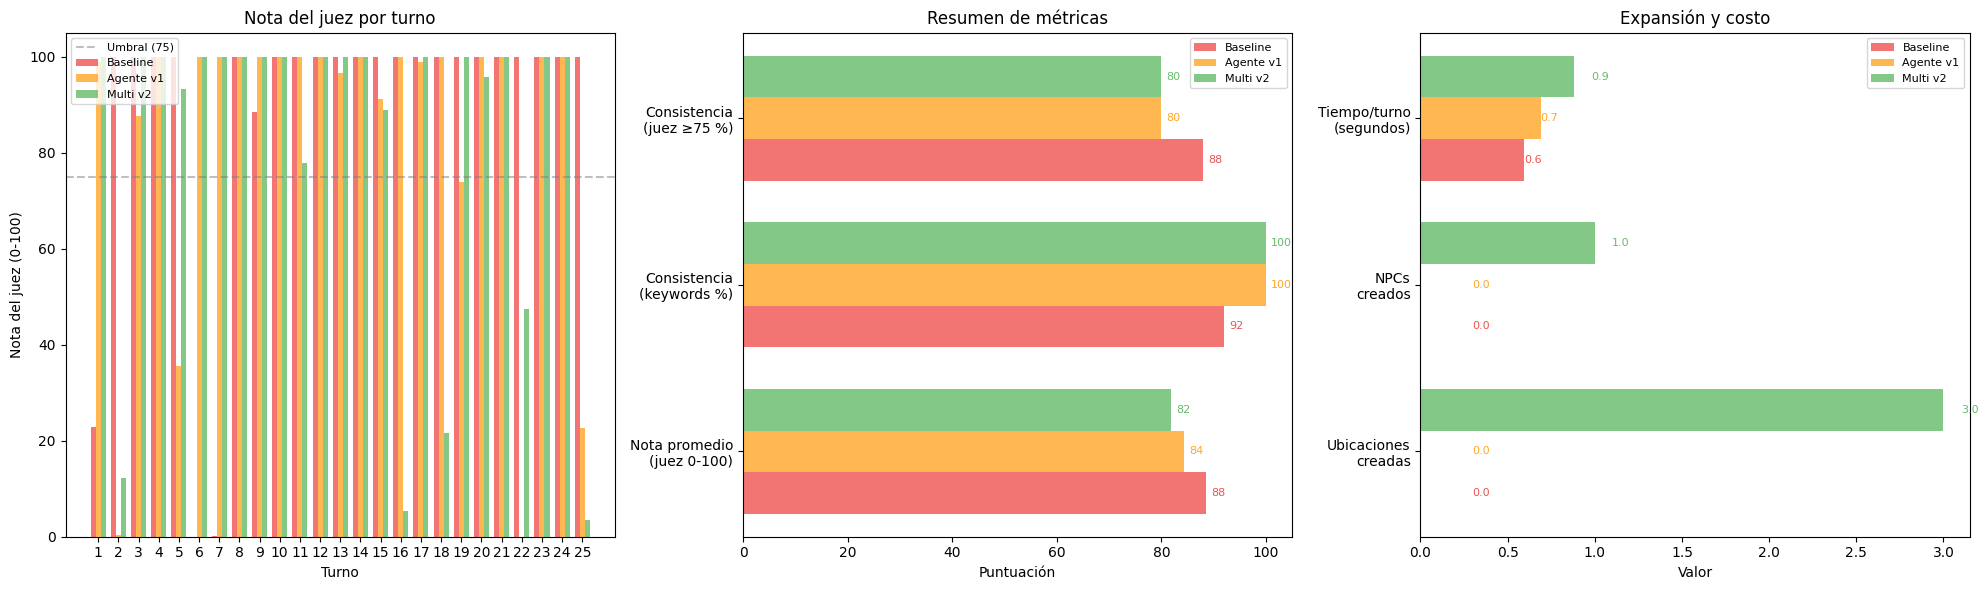

In [14]:
# ────────────────────────────────────────────────────────────────────────────
# 6.2 Gráficos comparativos
# ────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
colors = {"Baseline": "#ef5350", "Agente v1": "#FFA726", "Multi v2": "#66BB6A"}

# --- Panel 1: Nota del juez por turno ---
ax = axes[0]
x = range(1, n + 1)
w = 0.25
ax.bar([i - w for i in x], scores_b, w, label="Baseline", color=colors["Baseline"], alpha=0.8)
ax.bar(list(x), scores_v1, w, label="Agente v1", color=colors["Agente v1"], alpha=0.8)
ax.bar([i + w for i in x], scores_v2, w, label="Multi v2", color=colors["Multi v2"], alpha=0.8)
ax.axhline(75, color="gray", linestyle="--", alpha=0.5, label="Umbral (75)")
ax.set_xlabel("Turno")
ax.set_ylabel("Nota del juez (0-100)")
ax.set_title("Nota del juez por turno")
ax.legend(fontsize=8)
ax.set_xticks(list(x))

# --- Panel 2: Resumen de métricas ---
ax = axes[1]
metrics = ["Nota promedio\n(juez 0-100)", "Consistencia\n(keywords %)", "Consistencia\n(juez ≥75 %)"]
vals_b = [avg_b, b_ok_kw/n*100, ok_b/n*100]
vals_v1 = [avg_v1, v1_ok_kw/n*100, ok_v1/n*100]
vals_v2 = [avg_v2, v2_ok_kw/n*100, ok_v2/n*100]
y_pos = range(len(metrics))
h = 0.25
ax.barh([y - h for y in y_pos], vals_b, h, label="Baseline", color=colors["Baseline"], alpha=0.8)
ax.barh(list(y_pos), vals_v1, h, label="Agente v1", color=colors["Agente v1"], alpha=0.8)
ax.barh([y + h for y in y_pos], vals_v2, h, label="Multi v2", color=colors["Multi v2"], alpha=0.8)
for i, (vb, v1, v2) in enumerate(zip(vals_b, vals_v1, vals_v2)):
    ax.text(vb + 1, i - h, f"{vb:.0f}", va="center", fontsize=8, color=colors["Baseline"])
    ax.text(v1 + 1, i, f"{v1:.0f}", va="center", fontsize=8, color=colors["Agente v1"])
    ax.text(v2 + 1, i + h, f"{v2:.0f}", va="center", fontsize=8, color=colors["Multi v2"])
ax.set_yticks(list(y_pos))
ax.set_yticklabels(metrics)
ax.set_xlabel("Puntuación")
ax.set_title("Resumen de métricas")
ax.legend(fontsize=8)

# --- Panel 3: Expansión del mundo ---
ax = axes[2]
expansion_metrics = ["Ubicaciones\ncreadas", "NPCs\ncreados", "Tiempo/turno\n(segundos)"]
n_locs_created = len(dm_v2.expansion_log)
n_npcs_created = len(game_state.get("npcs_created", []))
exp_b = [0, 0, t_b/len(baseline_dm.turn_times)]
exp_v1 = [0, 0, t_v1/len(agent_v1.turn_times)]
exp_v2 = [n_locs_created, n_npcs_created, t_v2/len(dm_v2.turn_times)]
y_pos2 = range(len(expansion_metrics))
ax.barh([y - h for y in y_pos2], exp_b, h, label="Baseline", color=colors["Baseline"], alpha=0.8)
ax.barh(list(y_pos2), exp_v1, h, label="Agente v1", color=colors["Agente v1"], alpha=0.8)
ax.barh([y + h for y in y_pos2], exp_v2, h, label="Multi v2", color=colors["Multi v2"], alpha=0.8)
for i, (vb, v1, v2) in enumerate(zip(exp_b, exp_v1, exp_v2)):
    ax.text(max(vb, 0.3), i - h, f"{vb:.1f}", va="center", fontsize=8, color=colors["Baseline"])
    ax.text(max(v1, 0.3), i, f"{v1:.1f}", va="center", fontsize=8, color=colors["Agente v1"])
    ax.text(max(v2, 0.3) + 0.1, i + h, f"{v2:.1f}", va="center", fontsize=8, color=colors["Multi v2"])
ax.set_yticks(list(y_pos2))
ax.set_yticklabels(expansion_metrics)
ax.set_xlabel("Valor")
ax.set_title("Expansión y costo")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 7. Demo interactiva

Ejecutar la función para jugar con el multi-agente v2.

In [15]:
# ────────────────────────────────────────────────────────────────────────────
# 7. Demo interactiva (no se ejecuta en batch)
# ────────────────────────────────────────────────────────────────────────────

def demo_interactiva_v2():
    """Demo interactiva con el multi-agente v2. Ejecutar manualmente."""
    dm = MultiAgentDM(app_v2)
    print("=" * 60)
    print("  DUNGEON MASTER v2 — Multi-Agente con Mundo Dinámico")
    print("  Escribe acciones. Intenta buscar puertas escondidas!")
    print("  'salir' para terminar, 'mapa' para ver el mundo.")
    print("=" * 60)

    intro = dm.play("Comienzo mi aventura. Describe donde estoy.")
    print(f"\nDM: {intro}")
    print(f"\n{_state_summary()}")

    while True:
        try:
            action = input("\n> Tu accion: ").strip()
        except (EOFError, KeyboardInterrupt):
            break
        if not action or action.lower() == "salir":
            print("\nFin de la partida.")
            break
        if action.lower() == "mapa":
            print(f"\n{_world_summary()}")
            for loc, data in world["locations"].items():
                tag = " [NUEVO]" if data.get("dynamic") else ""
                print(f"  {loc}{tag}: {data['description'][:60]}... -> {data['connections']}")
            continue
        response = dm.play(action)
        print(f"\nDM: {response}")
        print(f"\n{_state_summary()}")

# demo_interactiva_v2()  # descomentar para jugar

## 8. Conclusiones

*Se actualizarán tras la ejecución completa.*

## 9. Declaración de uso de IAG

Este proyecto fue desarrollado con asistencia de inteligencia artificial generativa:

- **Claude Code (Anthropic)**: planificación de la arquitectura multi-agente, implementación del grafo LangGraph con múltiples nodos especializados, diseño de las herramientas de expansión dinámica del mundo, y configuración de la evaluación.
- **Ollama + qwen2.5:7B**: modelo local usado tanto para los agentes del juego como para el LLM-as-judge.

Todo el código fue revisado, ajustado y verificado por el estudiante.